# Lecture 6 (10 Oct 2026) — pandas

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kosavina/hse-python-2026/blob/main/Lecture_6.ipynb)

pandas is NumPy with **labels**: every row has a name (the *index*) and every column has a name. It is what the model reaches for whenever data comes from a file. As with NumPy, your job is to **read** what it writes. When a pandas line looks right and is wrong, the reason is almost always one of three things.

- **index** — pandas lines values up by **label**, not by position. Two tables with different labels give `NaN`, not an error.
- **dtype** — did the dates and numbers come in as dates and numbers, or as text? (`.dtypes`)
- **rows** — how many rows went in, and how many came out? `merge`, `dropna` and `groupby` all change the count. (`.shape`, `len`)

### Today

1. From list, array and dict to `Series` and `DataFrame`
2. Reading a file
3. The anatomy of a DataFrame, and dtypes
4. A column is a `Series`
5. Operators and chaining
6. A meaningful index; new columns
7. Selecting: `loc` and `iloc`
8. Alignment by label
9. Combining tables: `concat`, `merge`, `join`
10. `groupby`
11. **pandas on SBER 2025**: the Lecture 4–5 numbers, in a few lines each

> **Rule for this notebook.** Wherever you see **PREDICT**, write your answer down *before* running the cell. For pandas the prediction is usually **how many rows** come out, or **what the index is**.

---
## 1 · From list, array and dict to `Series` and `DataFrame`

The same three numbers four ways. A list has positions; an array has positions and one dtype; a dict has labels. A `Series` has both positions and labels, and a `DataFrame` is a table of `Series` that share one index.

In [ ]:
import numpy as np
import pandas as pd

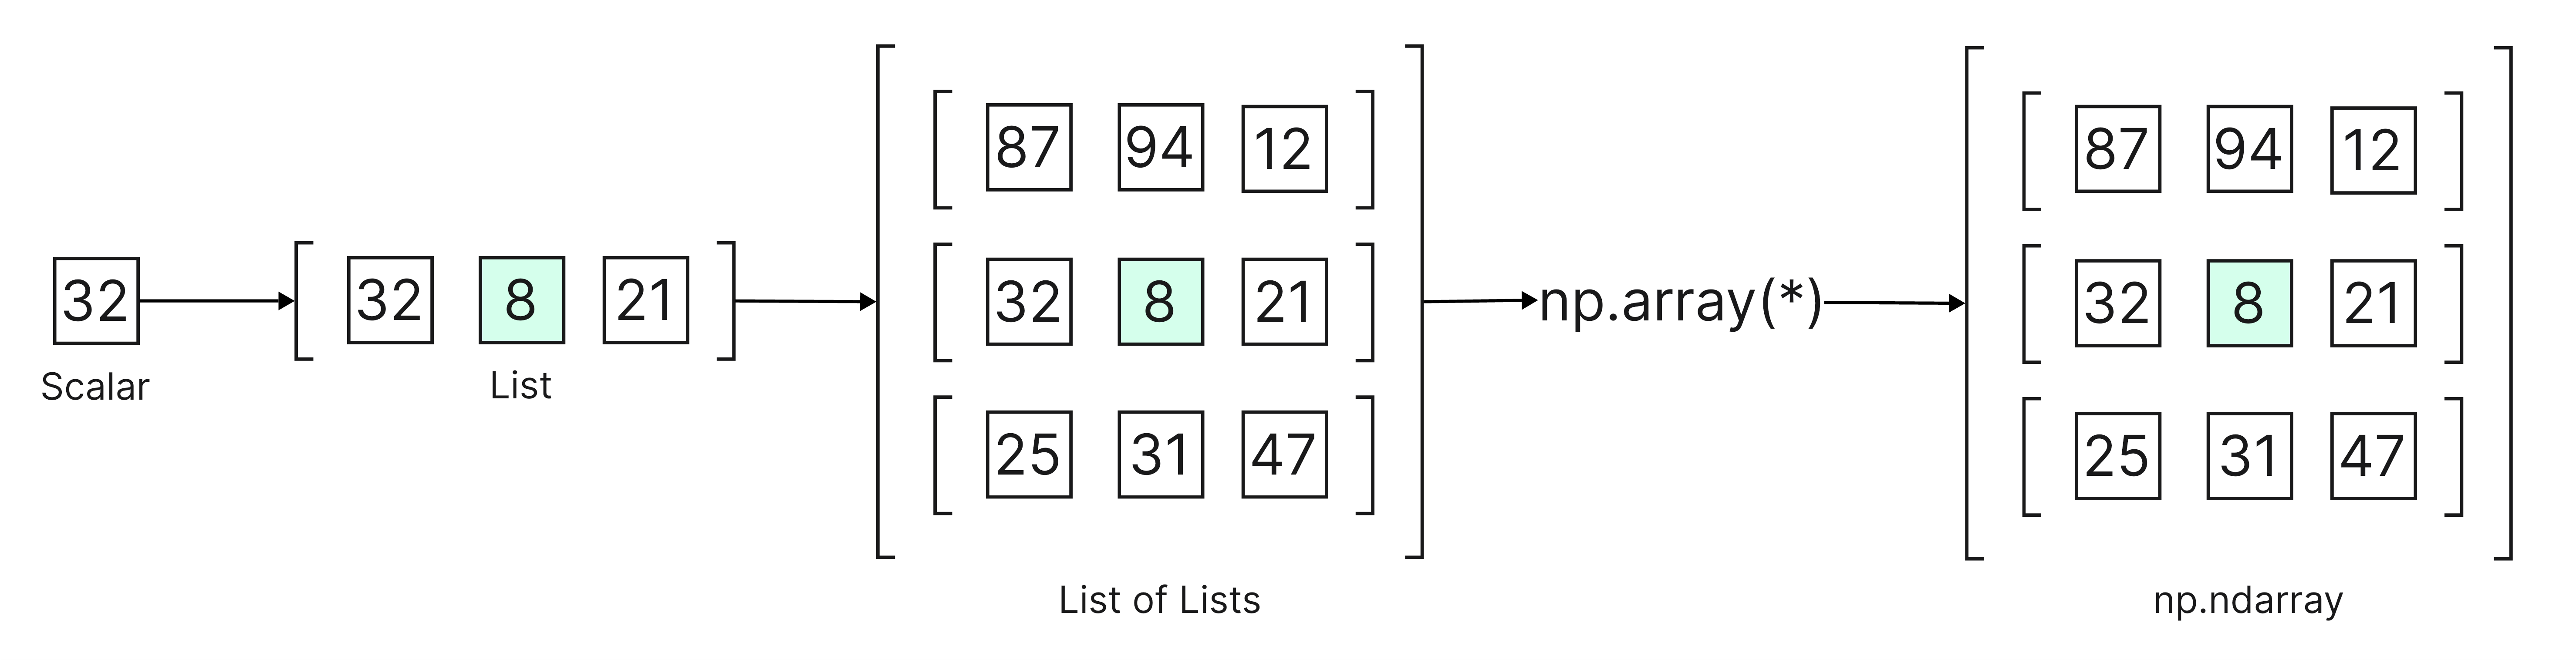

In [ ]:
x = 32
l = [32, 8, 21]
ll = [
    [87, 94, 12],
    [32,  8, 21],
    [25, 31, 47],
]
arr = np.array(ll)

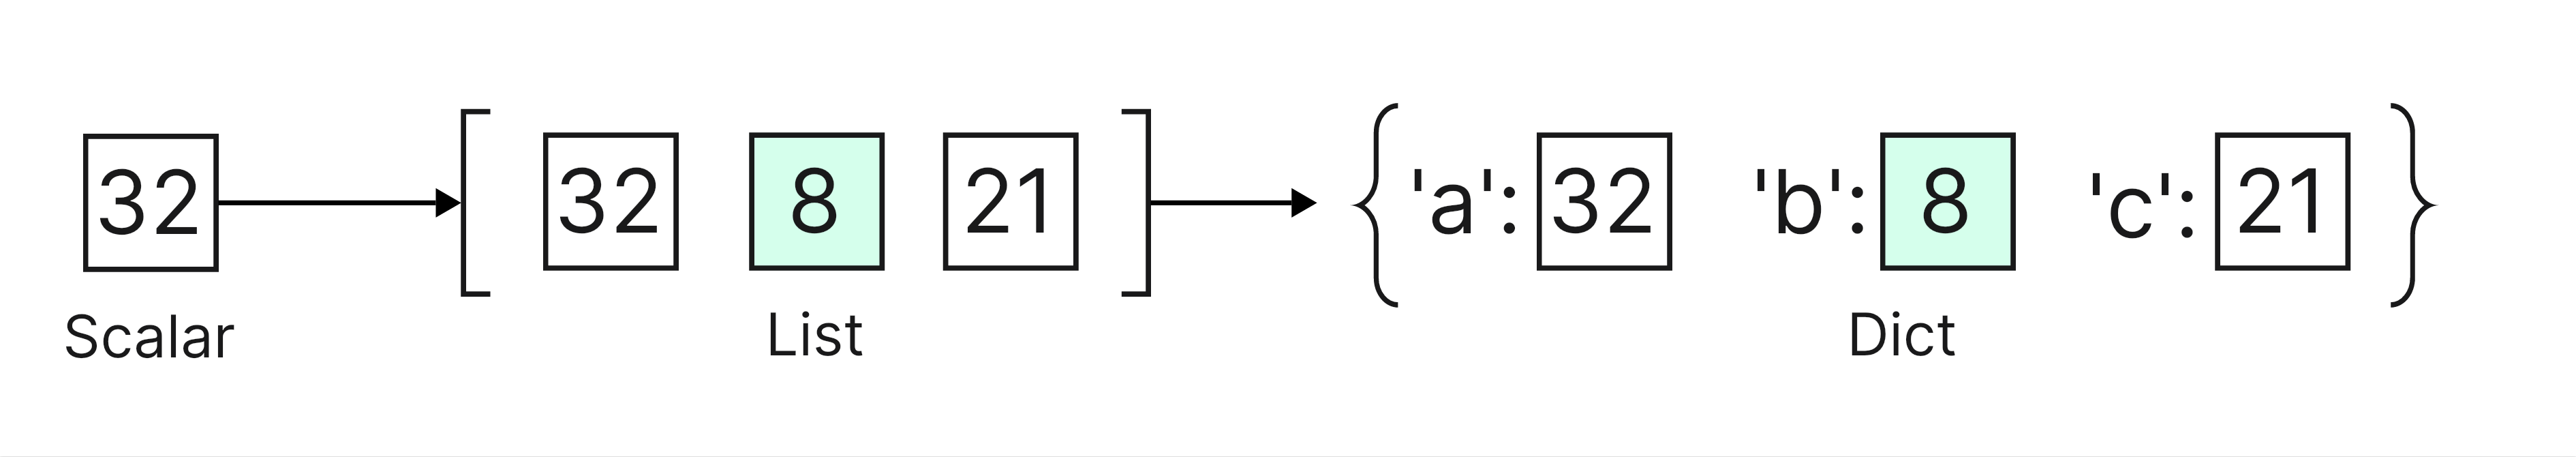

In [ ]:
x = 32
l = [32, 8, 21]
d = {'a': 32, 'b': 8, 'c': 21}

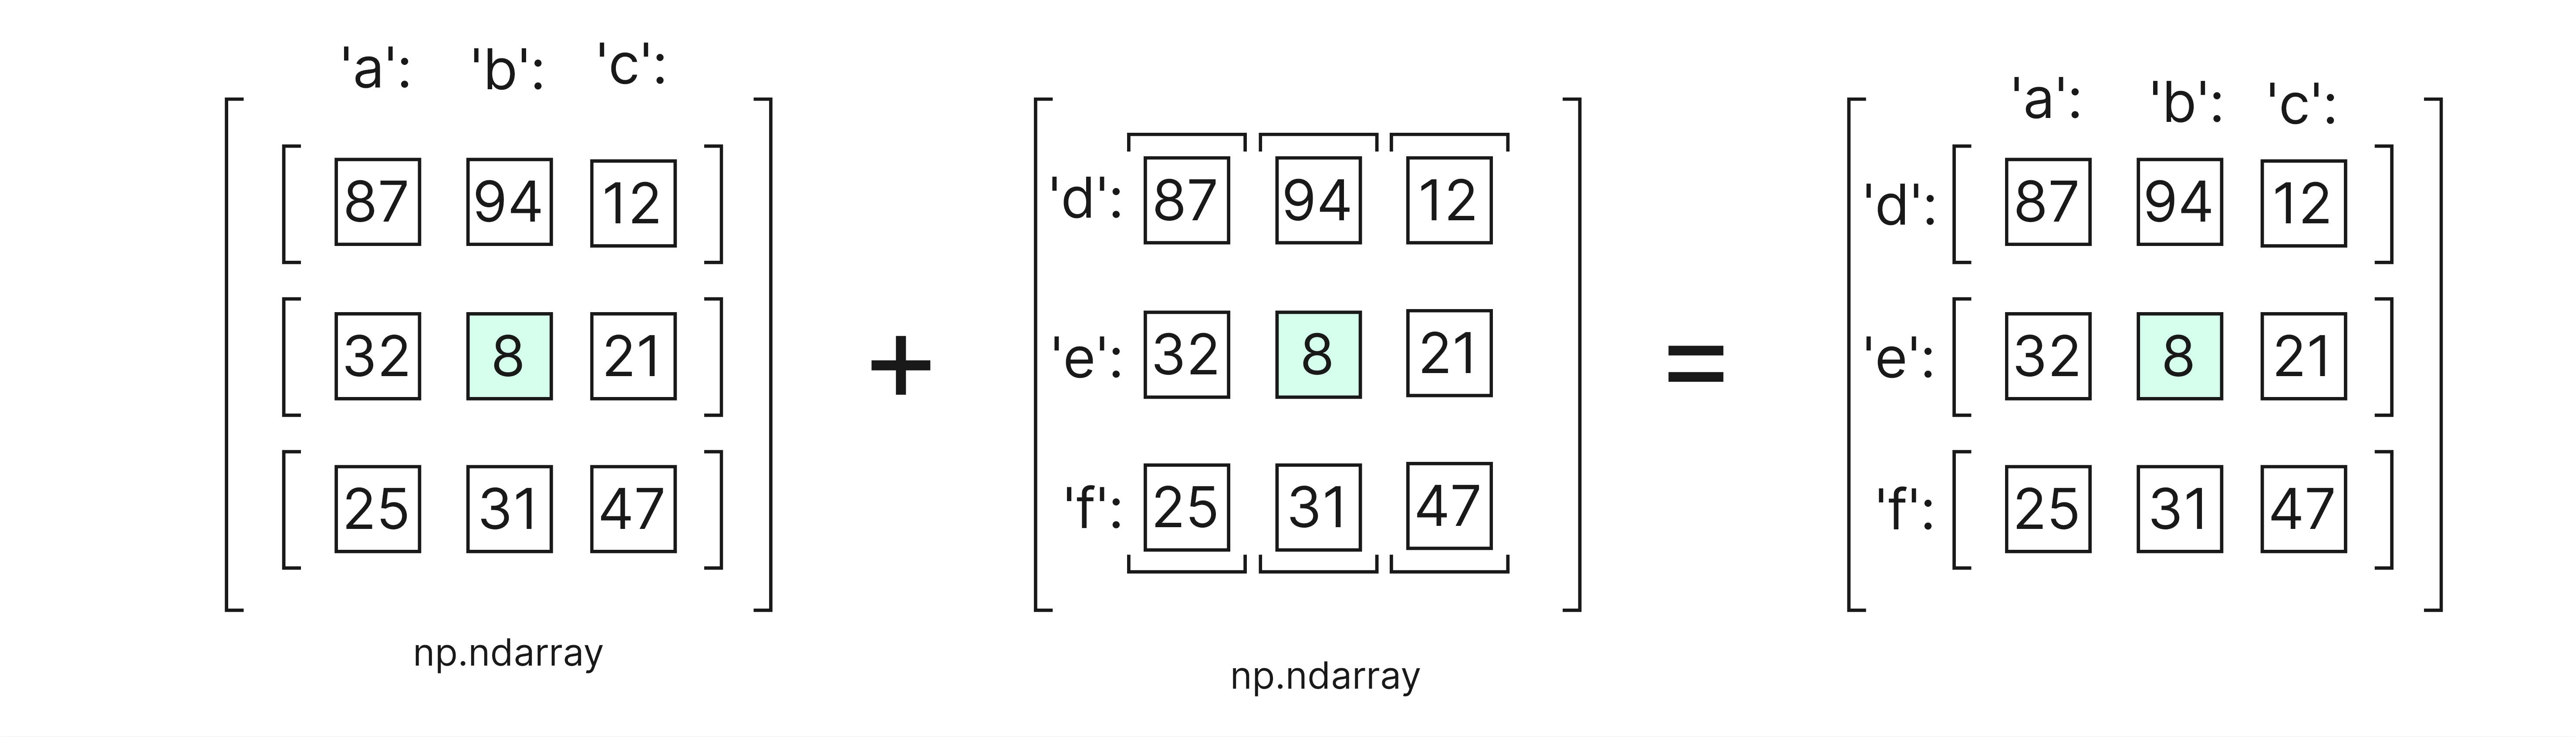

In [ ]:
df = pd.DataFrame(arr, index=['a', 'b', 'c'], columns=['d', 'e', 'f'])

---
## 2 · Reading a file

`pd.read_csv` turns a file into a `DataFrame`. The examples in sections 2–8 use public datasets from the *Pandas Cookbook*: films, US colleges and baseball. The cell below downloads them; it replaces last year's Colab-only `%%shell` cell, so it also works on your laptop.

In [ ]:
# Data for sections 2-8: a few CSV files from the "Pandas Cookbook" repository.
# Downloads each file into ./data the first time; skips the ones already there.
import os, urllib.request

COOKBOOK_URL = "https://raw.githubusercontent.com/PacktPublishing/Pandas-Cookbook/e3bfd0750df01b30eb778b86f5314f2a1f2eacb0/data/"
os.makedirs("data", exist_ok=True)
for name in ["movie.csv", "college.csv", "baseball14.csv", "baseball15.csv", "baseball16.csv"]:
    path = os.path.join("data", name)
    if not os.path.exists(path):
        urllib.request.urlretrieve(COOKBOOK_URL + name, path)
print(sorted(os.listdir("data")))

Read `data/movie.csv`

In [ ]:
!head -n 5 ./data/movie.csv

## Dissecting the anatomy of a DataFrame

### Change options to get specific output for book

In [ ]:
pd.set_option('display.max_columns', 8)
pd.set_option('display.max_rows', 10)

In [ ]:
movie = pd.read_csv('data/movie.csv')

In [ ]:
movie.head()

---
## 3 · The anatomy of a DataFrame, and dtypes

Three parts: the **index** (row labels), the **columns** (column labels) and the **values** (a NumPy array underneath). And one dtype per column.

## Accessing the main DataFrame components

In [ ]:
movie.head()

In [ ]:
columns = movie.columns
index = movie.index
data = movie.values

In [ ]:
columns

In [ ]:
index

In [ ]:
data

In [ ]:
type(index)

In [ ]:
type(columns)

In [ ]:
type(data)

## Understanding data types

In [ ]:
movie = pd.read_csv('data/movie.csv')

In [ ]:
movie.dtypes

In [ ]:
movie.dtypes.value_counts()

### dtypes on our own file

The SBER file from Lectures 1–5: 254 trading days of 2025, columns `TRADEDATE, OPEN, HIGH, LOW, CLOSE, VOLUME, VALUE`.

**PREDICT.** With no options, what dtype will `read_csv` give the `TRADEDATE` column?

In [ ]:
# SBER loader. Tries the local cached file first, then the course repository.
import os, urllib.request
import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/kosavina/hse-python-2026/main/data/SBER_2025_daily.csv"
DATA_FILE = "SBER_2025_daily.csv"
for candidate in (DATA_FILE, os.path.join("data", DATA_FILE), os.path.join("..", "data", DATA_FILE)):
    if os.path.exists(candidate):
        DATA_FILE = candidate
        break
else:
    urllib.request.urlretrieve(DATA_URL, os.path.join("data", DATA_FILE))
    DATA_FILE = os.path.join("data", DATA_FILE)

In [ ]:
raw = pd.read_csv(DATA_FILE)       # no options: let pandas guess every type
print(raw.shape)
print(raw.dtypes)

The prices are floats and the volume is an integer, but the dates came in as **text**: `object` in pandas 2, `str` in pandas 3. Text dates sort as strings and can't be used for date arithmetic. Two options fix both problems: parse the dates, and make them the index.

In [ ]:
sber = pd.read_csv(DATA_FILE, parse_dates=["TRADEDATE"], index_col="TRADEDATE")
print(sber.shape)
print(sber.index.dtype)
sber.head()

In [ ]:
# Checks worth writing after every load: the row count, and that each date appears once, in order.
assert sber.shape == (254, 6), sber.shape
assert sber.index.is_unique and sber.index.is_monotonic_increasing
assert (sber["HIGH"] >= sber["LOW"]).all(), "a HIGH below its LOW would mean the columns are mixed up"

`TRADEDATE` is no longer a column: it is the **index**, so the table has 6 columns. From now on every row is named by its date.

---
## 4 · A column is a `Series`

One column of a `DataFrame` is a `Series`: values plus the same index. Most of what you do to data is a `Series` method.

## Selecting a single column of data as a Series

In [ ]:
movie = pd.read_csv('data/movie.csv')

In [ ]:
movie

In [ ]:
movie['director_name']

In [ ]:
movie.director_name

In [ ]:
type(movie)

In [ ]:
type(movie['director_name'])

### There's more

In [ ]:
director = movie['director_name']
director.name

In [ ]:
type(director.to_frame())

In [ ]:
movie = pd.read_csv('data/movie.csv')
director = movie['director_name']
actor_1_fb_likes = movie['actor_1_facebook_likes']

In [ ]:
director.head()

In [ ]:
actor_1_fb_likes.head()

In [ ]:
director.value_counts()

In [ ]:
actor_1_fb_likes.value_counts()

In [ ]:
director.size

In [ ]:
movie.shape

In [ ]:
director.shape

In [ ]:
len(director)

In [ ]:
director.count()

In [ ]:
actor_1_fb_likes.count()

In [ ]:
actor_1_fb_likes.quantile()

In [ ]:
actor_1_fb_likes.min(), actor_1_fb_likes.max(), \
actor_1_fb_likes.mean(), actor_1_fb_likes.median(), \
actor_1_fb_likes.std(), actor_1_fb_likes.sum()

In [ ]:
actor_1_fb_likes.shape

In [ ]:
actor_1_fb_likes.describe()

In [ ]:
director.describe()

In [ ]:
actor_1_fb_likes.quantile(.2)

In [ ]:
actor_1_fb_likes.quantile([.1, .2, .3, .4, .5, .6, .7, .8, .9])

In [ ]:
director.isnull()

In [ ]:
actor_1_fb_likes.count()

In [ ]:
actor_1_fb_likes_filled = actor_1_fb_likes.fillna(0)
actor_1_fb_likes_filled.count()

In [ ]:
actor_1_fb_likes_filled.shape

In [ ]:
actor_1_fb_likes_dropped = actor_1_fb_likes.dropna()
actor_1_fb_likes_dropped.size

**Rows, or non-missing values?** `len(s)`, `s.size` and `s.shape[0]` count **rows**. `s.count()` counts the values that are **not missing**. When the two differ, there are `NaN`s in the column, and every `mean` and `sum` silently skips them.

### There's more...

In [ ]:
director.value_counts(normalize=True)

In [ ]:
director

In [ ]:
director.hasnans

---
## 5 · Operators and chaining

Arithmetic and comparisons work element by element, as in NumPy. Methods return new objects, so they chain.

## Working with operators on a Series

### Getting ready...

In [ ]:
movie = pd.read_csv('data/movie.csv')
imdb_score = movie['imdb_score']
imdb_score

In [ ]:
imdb_score + 1

In [ ]:
imdb_score * 2.5

In [ ]:
imdb_score // 7

In [ ]:
imdb_score > 7

In [ ]:
director = movie['director_name']

In [ ]:
director

In [ ]:
director == 'James Cameron'

## Chaining Series methods together

In [ ]:
movie = pd.read_csv('data/movie.csv')
actor_1_fb_likes = movie['actor_1_facebook_likes']
director = movie['director_name']

In [ ]:
director.value_counts().value_counts()

In [ ]:
director.value_counts().head(3)

In [ ]:
actor_1_fb_likes.isnull().value_counts()

In [ ]:
actor_1_fb_likes.dtype

In [ ]:
actor_1_fb_likes.fillna(0)\
                .astype(int)\
                .head()

In [ ]:
actor_1_fb_likes.isnull().mean()

The last cell is the NumPy rule from Lecture 4 again: **the mean of a boolean column is a share.** `isnull().mean()` is the share of missing values; `(r > 0).mean()` will be the share of up days.

---
## 6 · A meaningful index; new columns

An index of row numbers says nothing. An index of film titles, or of dates, lets you ask for a row by name.

## Making the index meaningful

In [ ]:
movie = pd.read_csv('data/movie.csv')

In [ ]:
movie

In [ ]:
movie.shape

In [ ]:
movie2 = movie.set_index('movie_title')
movie2

In [ ]:
pd.read_csv('data/movie.csv').set_index('movie_title')

In [ ]:
pd.read_csv('data/movie.csv', index_col='movie_title')

In [ ]:
movie2.reset_index(drop=True)

# Renaming row and column names

In [ ]:
movie = pd.read_csv('data/movie.csv', index_col='movie_title')

In [ ]:
idx_rename = {'Avatar':'Ratava', 'Spectre': 'Ertceps'}
col_rename = {'director_name':'Director Name',
              'num_critic_for_reviews': 'Critical Reviews'}

In [ ]:
movie.rename(index=idx_rename,
             columns=col_rename,
             ).head()

# Creating and deleting columns

In [ ]:
movie = pd.read_csv('data/movie.csv')

In [ ]:
movie['has_seen'] = 0

In [ ]:
movie.has_seen

In [ ]:
movie['actor_director_facebook_likes'] = (movie['actor_1_facebook_likes'] +
                                          movie['actor_2_facebook_likes'] +
                                          movie['actor_3_facebook_likes'] +
                                          movie['director_facebook_likes'])

In [ ]:
movie['actor_director_facebook_likes'].isnull().sum()

In [ ]:
movie['actor_director_facebook_likes'].fillna(0)

In [ ]:
movie['actor_director_facebook_likes'] = movie['actor_director_facebook_likes'].fillna(0)

In [ ]:
movie['is_cast_likes_more'] = (movie['cast_total_facebook_likes'] >=
                                  movie['actor_director_facebook_likes'])

In [ ]:
movie['is_cast_likes_more'].any()

In [ ]:
movie = movie.drop('actor_director_facebook_likes', axis='columns')

In [ ]:
profit_index = movie.columns.get_loc('gross') + 1
profit_index

In [ ]:
movie.insert(loc=profit_index,
                 column='profit',
                 value=movie['gross'] - movie['budget'])

In [ ]:
movie.head()

---
## 7 · Selecting: `loc` and `iloc`

**`.iloc` selects by position** (integers, like a list). **`.loc` selects by label** (whatever the index holds: names, dates). Say which one you mean; `df[...]` on its own guesses.

## Selecting Series data

In [ ]:
college = pd.read_csv('data/college.csv', index_col='INSTNM')
city = college['CITY']
city.head()

In [ ]:
city.iloc[3]

In [ ]:
city.iloc[[10,20,30]]

In [ ]:
city.iloc[4:50:10]

In [ ]:
city

In [ ]:
city.loc['Heritage Christian University']

In [ ]:
city.loc['Alabama State University':'Reid State Technical College':10]

# Selecting DataFrame rows

In [ ]:
college = pd.read_csv('data/college.csv', index_col='INSTNM')
college.head()

In [ ]:
pd.options.display.max_rows = 6

In [ ]:
college.iloc[60]

In [ ]:
college.loc['University of Alaska Anchorage']

In [ ]:
college.iloc[[60, 99, 3]]

In [ ]:
labels = ['University of Alaska Anchorage',
          'International Academy of Hair Design',
          'University of Alabama in Huntsville']
college.loc[labels]

In [ ]:
college.iloc[99:102]

In [ ]:
start = 'International Academy of Hair Design'
stop = 'Mesa Community College'
college.loc[start:stop]

In [ ]:
college.iloc[[60, 99, 3]].index.tolist()

# Selecting DataFrame rows and columns simultaneously

In [ ]:
college = pd.read_csv('data/college.csv', index_col='INSTNM')
college.iloc[:3, :4]

In [ ]:
college.loc[:'Amridge University', :'MENONLY']

In [ ]:
college.iloc[:, [4,6]].head()

In [ ]:
college.loc[:, ['WOMENONLY', 'SATVRMID']]

In [ ]:
college.iloc[[100, 200], [7, 15]]

In [ ]:
rows = ['GateWay Community College', 'American Baptist Seminary of the West']
columns = ['SATMTMID', 'UGDS_NHPI']
college.loc[rows, columns]

In [ ]:
college.iloc[5, -4]

In [ ]:
college.loc['The University of Alabama', 'PCTFLOAN']

# Selecting data with both integers and labels

In [ ]:
college = pd.read_csv('data/college.csv', index_col='INSTNM')

In [ ]:
college.columns.get_loc('UGDS_WHITE')

In [ ]:
col_start = college.columns.get_loc('UGDS_WHITE')
col_end = college.columns.get_loc('UGDS_UNKN') + 1
col_start, col_end

In [ ]:
college.iloc[:5, col_start:col_end]

In [ ]:
row_start = college.index[10]
row_end = college.index[15]
print(row_start)
college.loc[row_start:row_end, 'UGDS_WHITE':'UGDS_UNKN']

### `loc` includes the end

**PREDICT.** How many rows does each line give? The first trading days of 2025 are 3, 6, 8, 9 and 10 January.

In [ ]:
print(len(sber.iloc[0:3]))                        # positions 0, 1, 2
print(len(sber.loc["2025-01-03":"2025-01-09"]))   # labels from 3 Jan to 9 Jan

3 and 4. `iloc` follows the half-open rule from Lecture 2: the stop position is excluded. `loc` **includes** the stop label. With labels this is what you want: "from 3 January to 9 January" means both days.

With a date index, `loc` also accepts a part of a date: a month, or a year.

In [ ]:
nov = sber.loc["2025-11"]                 # every trading day of November
print(nov.shape)
print(nov.index[0].strftime("%Y-%m-%d %A"))

November has 20 trading days, the same number as in Lecture 5. The first of them is a **Saturday**: 1 November 2025 was a working day on MOEX. Keep it in mind for section 10.

In [ ]:
college = pd.read_csv('data/college.csv')
columns = college.columns
columns

In [ ]:
columns.values

In [ ]:
columns[5]

In [ ]:
columns[[1,8,10]]

In [ ]:
columns[-7:-4]

In [ ]:
columns.min(), columns.max(), columns.isnull().sum()

In [ ]:
columns + '_A'

In [ ]:
columns > 'G'

> ⚠️ **This cell is supposed to raise an error.** That is the lesson. Run it, read the error type and the message, and move on — nothing is broken.

In [ ]:
columns[1] = 'city'

An index can't be changed in place, element by element. To rename, use `.rename(...)` from section 6, or assign a whole new list to `.columns`.

---
## 8 · Alignment by label

**The most important section today.** When pandas combines two `Series`, it first matches their labels, then computes. Labels that are on one side only give `NaN`. No error, no warning.

In [ ]:
# Sections 2 and 7 limited the display to 10 and then 6 rows. Back to the defaults.
pd.reset_option("display.max_rows")
pd.reset_option("display.max_columns")

## Series ops

In [ ]:
s1 = pd.Series([1, 2, 3])
s2 = pd.Series([4, 5, 6])

In [ ]:
s1.values

In [ ]:
s2.values

In [ ]:
s1.values + s2.values

In [ ]:
s1 + s2

In [ ]:
s1 = pd.Series([1, 2], index=[0, 1])
s2 = pd.Series([3, 4], index=[1, 2])

In [ ]:
s1.values + s2.values

In [ ]:
s1 + s2

In [ ]:
s1 = pd.Series([1, 2, 3], index=['a', 'b', 'c'])
s2 = pd.Series([4, 5, 6], index=['a', 'b', 'c'])

In [ ]:
s1 + s2

In [ ]:
s1 = pd.Series([1, 2, 3, 4], index=['a', 'b', 'b', 'c'])
s2 = pd.Series([4, 5, 6, 7], index=['a', 'b', 'b', 'c'])

s1 + s2

In [ ]:
s1 = pd.Series([1, 2, 3, 4], index=['a', 'b', 'c', 'b'])
s2 = pd.Series([4, 5, 6, 7], index=['a', 'b', 'b', 'c'])

s1 + s2

In [ ]:
s1 = pd.Series([1, 2, 3], index=['a', 'b', 'c'])
s2 = pd.Series([4, 5, 6], index=['b', 'c', 'd'])

In [ ]:
s1 + s2

In [ ]:
s1.reset_index(drop=True) + s2.reset_index(drop=True)

In [ ]:
s1 + s2

In [ ]:
s1.add(s2, fill_value=0)

## Producing Cartesian products

In [ ]:
s1 = pd.Series(index=list('aaab'), data=np.arange(4))
s1

In [ ]:
s2 = pd.Series(index=list('cababb'), data=np.arange(6))
s2

In [ ]:
s1 + s2

In [ ]:
(s1 + s2).index

In [ ]:
s1 = pd.Series(index=list('aaabb'), data=np.arange(5))
s2 = pd.Series(index=list('aaabb'), data=np.arange(5))
s1 + s2

In [ ]:
s1 = pd.Series(index=list('aaabb'), data=np.arange(5))
s2 = pd.Series(index=list('bbaaa'), data=np.arange(5))
s1 + s2

## Filling values with unequal indexes

In [ ]:
baseball_14 = pd.read_csv('data/baseball14.csv', index_col='playerID')
baseball_15 = pd.read_csv('data/baseball15.csv', index_col='playerID')
baseball_16 = pd.read_csv('data/baseball16.csv', index_col='playerID')
baseball_14.head()

In [ ]:
baseball_14.shape

In [ ]:
baseball_15.shape

In [ ]:
baseball_14 + baseball_15

In [ ]:
(baseball_14 + baseball_15).shape

In [ ]:
baseball_14.index.difference(baseball_15.index)

In [ ]:
hits_14 = baseball_14['H']
hits_15 = baseball_15['H']
hits_16 = baseball_16['H']
hits_14.head()

In [ ]:
(hits_14 + hits_15).head()

In [ ]:
hits_14.add(hits_15, fill_value=0).head()

In [ ]:
hits_total = hits_14.add(hits_15, fill_value=0).add(hits_16, fill_value=0)
hits_total.head()

In [ ]:
hits_total.hasnans

In [ ]:
s1 = pd.Series(index=['a', 'b', 'c', 'd'], data=[np.nan, 3, np.nan, 1])
s1

In [ ]:
s2 = pd.Series(index=['a', 'b', 'c'], data=[np.nan, 6, 10])
s2

In [ ]:
s1.add(s2, fill_value=5)

In [ ]:
df_14 = baseball_14[['G','AB', 'R', 'H']]
df_14.head()

In [ ]:
df_15 = baseball_15[['AB', 'R', 'H', 'HR']]
df_15.head()

In [ ]:
(df_14 + df_15).head(10).style.highlight_null('yellow')

In [ ]:
df_14.add(df_15, fill_value=0).head(10).style.highlight_null('yellow')

### Daily returns: the NumPy way does not carry over

In Lecture 4 the daily return was `close[1:] / close[:-1] - 1`: two slices of the same array, shifted by one day. Here is the same idea on a `Series`.

**PREDICT.** What values do you expect, and how many rows?

In [ ]:
close = sber["CLOSE"]
aligned = close.iloc[1:] / close.iloc[:-1] - 1
print(len(aligned))
aligned.describe()

Every return is **0**, with a `NaN` at each end. pandas did not divide "today by yesterday": it matched the **dates**, so it divided each day's close by **itself**. The two slices cover 254 dates between them; both contain 252 of them.

The pandas way is to move the values, not cut them: `shift(1)` puts yesterday's close on today's date. `pct_change()` does the same in one call.

In [ ]:
r_shift = close / close.shift(1) - 1
r = close.pct_change()
print(len(r), r.count())          # rows, and non-missing values
print(r.head(3))

assert (r - r_shift).abs().max() < 1e-12   # the same numbers
assert r.isna().sum() == 1        # the first day has no yesterday

**254 rows, 253 values.** NumPy gave 253 returns. pandas keeps all 254 dates and puts `NaN` on the first one, so the returns stay lined up with the dates. That is why in pandas there is no `dates[1:]`.

---
## 9 · Combining tables: `concat`, `merge`, `join`

`concat` glues tables along an axis and aligns the labels. `merge` matches rows by **key values**, as SQL `JOIN` does. `join` is `merge` on the index. After every one of them, ask: **how many rows came out?**

## Concat Series

In [ ]:
s1 = pd.Series([1, 2, 3], index=['a', 'b', 'c'])
s2 = pd.Series([4, 5], index=['b', 'c'])

In [ ]:
pd.concat([s1, s2])

In [ ]:
pd.concat([s1, s2], axis=1)

In [ ]:
s1 = pd.Series([1, 2, 3], index=['a', 'b', 'c'], name='col1')
s2 = pd.Series([4, 5, 6], index=['x', 'y', 'z'], name='col2')

In [ ]:
pd.concat([s1, s2])

In [ ]:
pd.concat([s1, s2], ignore_index=True)

In [ ]:
pd.concat([s1, s2], axis=1)

In [ ]:
pd.concat([s1, s2], axis=1, ignore_index=True)

## Merge DataFrames

In [ ]:
df1 = pd.DataFrame({'key': ['A', 'B', 'C'], 'value1': [1, 2, 3]})
df2 = pd.DataFrame({'key': ['B', 'C', 'D'], 'value2': [4, 5, 6]})

In [ ]:
df1

In [ ]:
df2

In [ ]:
pd.merge(df1, df2, left_on='key', right_on='key', how='outer')

In [ ]:
pd.merge(df1, df2, on='key', how='outer')

In [ ]:
pd.merge(df1, df2, left_on='key', right_on='key', how='inner')

In [ ]:
pd.merge(df1, df2, left_on='key', right_on='key', how='left')

In [ ]:
pd.merge(df1, df2, left_on='key', right_on='key', how='right')

In [ ]:
pd.merge(df1, df2, how='cross')

## Join DataFrames

In [ ]:
df1 = pd.DataFrame({'value1': [1, 2, 3]}, index=['A', 'B', 'C'])
df2 = pd.DataFrame({'value2': [4, 5, 6]}, index=['B', 'C', 'D'])

In [ ]:
df1.join(df2, how='outer')

In [ ]:
df1.join(df2, how='inner')

In [ ]:
df1.join(df2, how='left')

In [ ]:
df2.join(df1, how='right')

## Concat Dataframes

In [ ]:
df1 = pd.DataFrame({'A': [1, 2], 'B': [3, 4]})
df2 = pd.DataFrame({'A': [5, 6], 'B': [7, 8]})

In [ ]:
pd.concat([df1, df2])

In [ ]:
pd.concat([df1, df2], axis=1)

In [ ]:
df1 = pd.DataFrame({'A': [1, 2]}, index=['x', 'y'])
df2 = pd.DataFrame({'B': [3, 4]}, index=['y', 'z'])

In [ ]:
pd.concat([df1, df2], axis=1)

| | | |
| --- | --- | --- |
| Feature |	pd.concat() |	pd.merge() |
| Purpose |	Stack or align data vertically/horizontally	| SQL-like joins based on keys or conditions |
| Keys/Conditions |	Not required | Required for merging |
| Index Alignment |	Aligns automatically (or ignores)	| Flexible: Can align by columns, indexes, or conditions |
| Join Types | Outer join for columns (default) |	Supports inner, outer, left, right |
| Flexibility	| Simple stacking/aligning | Highly flexible and feature-rich |

Use pd.concat() for simple concatenation and pd.merge() for more complex, key-based combinations.


### `concat(axis=1)`: series side by side

The everyday use of `concat`: put several `Series` with the same index into one table. Here, the close and its 20- and 50-day moving averages (Task 5 of Lecture 5).

**PREDICT.** How many rows does `table` have, and on which date does its first complete row (no `NaN`) fall?

In [ ]:
table = pd.concat(
    [close, close.rolling(20).mean(), close.rolling(50).mean()],
    axis=1, keys=["close", "sma20", "sma50"],
)
print(table.shape)
print(table.dropna().index[0].date())
table.iloc[47:52]

254 rows: `rolling` keeps every date and writes `NaN` where the window isn't full yet. The first complete row is 2025-03-14, day 50 of the file, the same start date as the backtest in Lecture 5.

### `merge`: adding the dividend

SBER paid a dividend of **34.84 ₽** per share for 2024. The record date was Friday 18 July 2025. Settlement is T+1, so 17 July was the last day to buy with the dividend, and from 18 July the share traded without it. The price fell from 327.05 to 309, -5.52%, which is close to the worst day of the year.

A dividend table usually lives in a different file. Here it is one row, typed in.

**PREDICT.** How many rows does each merge give?

In [ ]:
# SBER dividend for 2024: 34.84 RUB, record date 18.07.2025, so ex-date 18.07.2025 under T+1.
divs = pd.DataFrame({"TRADEDATE": pd.to_datetime(["2025-07-18"]), "DIV": [34.84]})

flat = sber.reset_index()           # merge works on columns, so TRADEDATE becomes a column again
inner = flat.merge(divs, on="TRADEDATE", how="inner")
left = flat.merge(divs, on="TRADEDATE", how="left", validate="one_to_one")
print(len(flat), len(inner), len(left))

`inner` keeps only the dates found in **both** tables: 1 row. `left` keeps every row of the left table: 254, with `NaN` in `DIV` on the days without a dividend.

Two habits make a merge safe:
- **`validate="one_to_one"`** makes pandas raise if a key appears twice on either side. (Duplicate keys multiply rows, as the duplicate labels did in section 8.)
- **Assert the row count.** After a left merge on a unique key, the count must not change.

In [ ]:
assert len(left) == len(sber), "a left merge on a unique key must not add or drop rows"

withdiv = left.set_index("TRADEDATE")
withdiv["DIV"] = withdiv["DIV"].fillna(0)

# Total return: on the ex-date the holder gets the new price plus the dividend.
tr = (withdiv["CLOSE"] + withdiv["DIV"]) / withdiv["CLOSE"].shift(1) - 1
print(f"18 Jul, price only   : {r.loc['2025-07-18']:+.2%}")
print(f"18 Jul, with dividend: {tr.loc['2025-07-18']:+.2%}")
print(f"2025, price only     : {(1 + r).prod() - 1:+.2%}")
print(f"2025, with dividend  : {(1 + tr).prod() - 1:+.2%}")

Expected: on 18 July -5.52% on price but +5.13% for the holder; for the year +10.16% on price and +22.58% with the dividend reinvested.

This is also why Lecture 4's maximum drawdown starts on **2025-07-17**: that is the last day the price still included the dividend. A price-only series treats a payout as a loss. When you ask a model for returns, say whether you want **price** or **total** return.

---
## 10 · `groupby`

**Split** the rows into groups by a key, **apply** a function to each group, **combine** the results into one table. One row per group comes out.

## Group by

In [ ]:
speeds = pd.DataFrame(
    [
        ("bird", "Falconiformes", 389.0),
        ("bird", "Psittaciformes", 24.0),
        ("mammal", "Carnivora", 80.2),
        ("mammal", "Primates", np.nan),
        ("mammal", "Carnivora", 58),
    ],
    index=["falcon", "parrot", "lion", "monkey", "leopard"],
    columns=("class", "order", "max_speed"),
)

In [ ]:
speeds

In [ ]:
for n, g in speeds.groupby("class"):
  print(n, g.max_speed.mean())

In [ ]:
speeds.groupby("class").max_speed.mean()


In [ ]:
speeds.groupby(["class", "order"]).mean()

### The monthly report card, in one `groupby`

In Lecture 3 this took a dictionary and three loops; in Lecture 5, masks and a loop over months. The key here is the **month of each date**, `sber.index.to_period("M")`.

**PREDICT.** How many rows does `monthly` have? Is `days` equal to `n_ret` in every month?

In [ ]:
sber["ret"] = sber["CLOSE"].pct_change()

monthly = sber.groupby(sber.index.to_period("M")).agg(
    days=("CLOSE", "size"),                    # rows in the month
    n_ret=("ret", "count"),                    # non-missing returns
    n_up=("ret", lambda x: (x > 0).sum()),
    last_close=("CLOSE", "last"),
    value=("VALUE", "sum"),
    volume=("VOLUME", "sum"),
)
monthly["vwap"] = monthly["value"] / monthly["volume"]
monthly["up_share"] = monthly["n_up"] / monthly["n_ret"]
monthly

12 rows, one per month. `days` and `n_ret` differ only in January: the first day has no return, and `count` skips the `NaN` while `size` doesn't.

### The monthly return, and the first month

**PREDICT.** What does `monthly["last_close"].pct_change()` give for January?

In [ ]:
print(monthly["last_close"].pct_change().head(2))

# Lecture 3 measured January from the first close in the file. shift() with fill_value does that.
first_close = sber["CLOSE"].iloc[0]
monthly["ret"] = monthly["last_close"] / monthly["last_close"].shift(1, fill_value=first_close) - 1
print(monthly["ret"].idxmax(), monthly["ret"].idxmin())

total = sber["CLOSE"].iloc[-1] / sber["CLOSE"].iloc[0] - 1
assert monthly["days"].sum() == len(sber), "the months must add up to the year"
assert abs((1 + monthly["ret"]).prod() - 1 - total) < 1e-12, "the months must chain to the year"

January is `NaN`: `pct_change` has no December 2024 to compare with. With the first close as the base, the best month is 2025-02 and the worst is 2025-09, the same as in Lecture 3, and the twelve months chain to 10.16%.

`resample("ME")` is the shortcut for grouping a date index by calendar period ("ME" = month end):

In [ ]:
sber["CLOSE"].resample("ME").last().head(3)

### Group by weekday

**PREDICT.** How many groups does this give?

In [ ]:
sber["ret"].groupby(sber.index.day_name()).agg(["count", "mean"])

Six, not five (in alphabetical order: `groupby` sorts the keys). The working Saturday is a group of **one** day, and its "average return" is that one day's return. Before you read anything into a group average, look at `count`.

---
## 11 · pandas on SBER 2025

The Lecture 4 numbers, again. Each one is a line or two, and the index carries the date along, so there is no `dates[1:]` and no `argmax` → date lookup.

In [ ]:
r = sber["CLOSE"].pct_change()

print(f"total return     {sber['CLOSE'].iloc[-1] / sber['CLOSE'].iloc[0] - 1:.2%}")
print(f"up days          {(r > 0).sum()} of {r.count()}  ({(r > 0).sum() / r.count():.1%})")
print(f"best day         {r.idxmax().date()}  {r.max():+.2%}")
print(f"worst day        {r.idxmin().date()}  {r.min():+.2%}")

Expected: 10.16%; 129 of 253; best 2025-02-12 (+6.78%); worst 2025-04-04 (-5.54%). Note `(r > 0).mean()` would divide by 254 rows, because the `NaN` counts as "not up". Here the denominator is `r.count()`.

### Volatility: `ddof` again

**PREDICT.** Lecture 4 gave 22.44 % with NumPy's default. What does pandas give?

In [ ]:
import numpy as np

print(f"pandas  r.std()            {r.std() * np.sqrt(252):.2%}")
print(f"NumPy   np.std(r.dropna()) {np.std(r.dropna().to_numpy()) * np.sqrt(252):.2%}")

22.48% against 22.44%. pandas divides by *n − 1* (`ddof=1`); NumPy divides by *n* (`ddof=0`). The data is the same and the method names look the same, but the defaults differ. Say which one you want.

### Maximum drawdown, and the yearly VWAP

In [ ]:
close = sber["CLOSE"]
drawdown = close / close.cummax() - 1           # cummax: the highest close so far
trough = drawdown.idxmin()
peak = close.loc[:trough].idxmax()
print(f"max drawdown {drawdown.min():.2%}  from {peak.date()} to {trough.date()}")

vwap_year = sber["VALUE"].sum() / sber["VOLUME"].sum()
print(f"yearly VWAP {vwap_year:.2f} RUB")
assert (drawdown <= 0).all() and drawdown.iloc[0] == 0

Expected: -13.81% from 2025-07-17 to 2025-10-08, and a yearly VWAP of 303.03 ₽, the same as in Lectures 4 and 5.

---
## Wrap-up: what to recognise, and how to ask

| You want | pandas |
|---|---|
| read a file | `pd.read_csv(path, parse_dates=[...], index_col=...)` |
| inspect | `.shape`, `.dtypes`, `.head()`, `.describe()`, `.index`, `.columns` |
| one column | `df["col"]` (a `Series`) |
| rows / non-missing | `len(s)`, `s.size` / `s.count()` |
| select by position / by label | `.iloc[i, j]` (half-open) / `.loc[label, "col"]` (end included) |
| filter | `df[df["col"] > x]` |
| missing values | `.isna()`, `.fillna()`, `.dropna()`, `.isna().mean()` |
| new column | `df["new"] = ...`, `.insert`, `.drop(columns=...)`, `.rename` |
| index | `.set_index`, `.reset_index`, `.sort_index` |
| yesterday on today's row | `.shift(1)`, `.pct_change()` |
| running / moving | `.cummax()`, `.cumprod()`, `.rolling(n).mean()` |
| side by side / on top | `pd.concat([...], axis=1)` / `pd.concat([...])` |
| match by key | `a.merge(b, on="key", how="left", validate="one_to_one")`, `a.join(b)` |
| per group | `df.groupby(key).agg(name=("col", "func"))`, `.resample("ME")` |

**When you ask a model for pandas code:**

1. **Describe the table**: "`sber` has a `DatetimeIndex` named `TRADEDATE`, 254 rows, float columns `OPEN … CLOSE`".
2. **Ask it to print `.shape`** after every step that can change the row count.
3. **For every merge, name the key, `how=` and `validate=`**, and assert the row count afterwards.
4. **Say what to do with the first `NaN`** (`pct_change`, `shift`, `rolling`), and say `ddof`.
5. **Ask for `.loc` / `.iloc`**, never `df[...][...] = ...` (chained assignment).
6. **Add one `assert` you know is true**: 254 rows, 20 days in November, a total return of 10.16 %.